# Искусственный интеллект — занятие 4
### Нейронные сети и TensorFlow/Keras

**Логика занятия:** чем TensorFlow отличается от PyTorch и какие уровни API есть в Keras → сборка первой нейронной сети (нейрон, слои, активации) → компиляция, обучение по эпохам и ранняя остановка → классификация `files/res_oval.dat`, метрики и дисбаланс классов.

## 1. TensorFlow и PyTorch

Для нейронных сетей есть две основные библиотеки.

**TensorFlow** сам определяет, на каком железе выполняется, и оптимизирует программу под него: что держать в памяти, что считать на CPU, а что отправить на GPU. Для учебных задач это удобно — код не зависит от конкретной машины.

**PyTorch** — стандарт де-факто в индустрии: на нём пишет большинство, в том числе крупные компании. Но распределение вычислений по железу (память, CPU, GPU) там полностью на программисте. У PyTorch фактически один уровень сложности — сразу тяжёлый: простые задачи описываются громоздко, зато сложные архитектуры делать легче, чем на TensorFlow. PyTorch изучается позже, в следующих семестрах.

## 2. Три уровня API Keras

`tf.keras` даёт три уровня сложности. В курсе мы пользуемся первым.

| Уровень | Что это | Когда нужен |
| --- | --- | --- |
| **Sequential** | модель — стопка слоёв, которые добавляются через `model.add(...)` | большинство задач; с него начинают |
| **Functional API** | слои соединяются в произвольный граф (`tf.keras.Model(inputs=..., outputs=...)`) | сложные архитектуры: ветвления, несколько входов и выходов; обучаются так же легко |
| **Subclassing** | свой класс — наследник `tf.keras.Model` с собственным методом `call` | произвольные операции над сетью и её обучением; нужен уровень PyTorch |

Если задача доросла до Subclassing, TensorFlow перестаёт быть удобным инструментом и нужен PyTorch — поэтому Subclassing в курсе не изучаем.

## 3. Установка `pydot`, импорт и версия TensorFlow

Первым делом ставим `pydot`: он нужен функции `tf.keras.utils.plot_model`, которая рисует схему сети. Без него `plot_model` падает с `ImportError` — в сохранённом выводе ниже видно, как это происходило до установки пакета. Кроме самого `pydot` для отрисовки схемы в системе должен стоять **graphviz**.

Затем импортируем `tensorflow` (сокращённо `tf`), `matplotlib.pyplot`, `numpy` и `pydot` — и печатаем версию через `tf.__version__`. В аудитории получились версии 2.19–2.21, API в пределах TensorFlow 2.x одинаков.

In [14]:
import sys
!{sys.executable} -m pip install pydot

In [17]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pydot

In [18]:
print(tf.__version__)


2.21.0


## 4. Черновик первой модели (`raw`-ячейка)

Ячейка ниже — черновик, набранный по ходу объяснения. Это набросок той же сети, которая дальше собирается аккуратно: в коде есть опечатки (`tf.keras.model` вместо `models`, `tf.kerass`, `opptimizer`, `le-1` вместо `1e-1`, `earlyStopping`, `callback` вместо `callbacks`) и незакрытая скобка, поэтому он не запустится как есть. Ячейка оставлена в исходном виде.

Что в ней за блоки:

- игрушечный датасет для регрессии: `N = 1000`, $y = 5{,}1x + 3 + \varepsilon$;
- `Sequential` → `Input(shape=(1,))` → `Dense(1, activation='linear')` — сеть из одного нейрона;
- `print(model.summary())` — сколько в модели параметров;
- `compile(optimizer=..., loss='mse')` — сборка модели и инициализация весов;
- `EarlyStopping` и `fit(..., validation_split=0.2, epochs=300)` — обучение с валидацией;
- графики `loss` и `val_loss` по эпохам.

## 5. Регрессия: первая нейронная сеть

**Нейрон** принимает вход $x$, умножает его на вес $w$, прибавляет смещение $b$ и пропускает результат через функцию активации $f$: $y = f(w \cdot x + b)$.

Сеть состоит из трёх частей: **входной слой**, **скрытые слои** и **выходной слой**. Входной слой полностью определяется данными: для одномерных входов пишем `Input(shape=(1,))` — запятая обязательна, потому что `shape` это кортеж. Скрытых слоёв в первой модели нет, выходной — один нейрон.

**Полносвязный слой** (`Fully Connected`) в Keras — это `Dense`: каждый его нейрон получает все входы предыдущего слоя. В `Dense` указывают число нейронов и функцию активации. Для **регрессии** выходной слой ничего не сжимает, поэтому активация `linear`: $y = \langle w, x \rangle + b$ — модель ищет те самые «волшебные коэффициенты» (в примере 5,1 и 3). Правило про `linear` касается только выходного слоя: скрытые слои могут иметь любые активации.

`model.summary()` показывает слои и число параметров: **Total params** — сколько всего, **Trainable params** — обучаемые, **Non-trainable params** — замороженные (любой параметр можно отключить от обучения флагом `trainable=False`). У одного нейрона на одномерном входе параметров два; каждый занимает 4 байта (`float32`), поэтому в таблице будет 8 байт.

Обучают модель двумя вызовами:

- `compile(optimizer=..., loss=..., metrics=...)` — собирает модель и инициализирует веса случайными числами. **Оптимизатор** ищет минимум (`Adam`), **функция потерь** говорит, что именно минимизировать (`mse` для регрессии), `metrics` — что печатать в логе;
- `fit(x, y, epochs=...)` — обучение. **Эпоха** — один полный прогон по обучающему датасету; `fit` возвращает объект `history` со значениями по эпохам (`history.history['loss']`).

У лосса нет содержательного смысла — важно только, что он **падает**. Если он растёт или стоит на месте, что-то сделано не так.

Первые строки следующей ячейки — заготовка той же регрессионной задачи: генерируется датасет $y = 5{,}1x + 3 + \varepsilon$. Затем в этой же ячейке `x` и `y` перекрываются данными из файла, то есть реально решается уже задача классификации.

## 6. Отложенная выборка и ранняя остановка

Обучающую выборку модель рано или поздно **переобучает**: на ней качество отличное, а на новых данных — плохое. Поэтому данные делят на обучающую и тестовую части (а если подбирают гиперпараметры — ещё и на валидационную) и тестовую при обучении не смотрят.

Часть обучающих данных можно отдать под валидацию прямо в `fit`:

- `validation_split=0.2` — TensorFlow случайно выделит 20% данных; параметры по ним подбираться не будут, считается только лосс `val_loss`.

Чтобы не учиться «до посинения», используют **раннюю остановку** (`EarlyStopping`):

- `monitor='val_loss'` — следим за валидационным лоссом;
- `mode='min'` — ищем минимум (для лосса всегда минимум, для метрик — зависит от метрики);
- `patience=5` — сколько ещё эпох терпеть после найденного минимума: без этого нельзя убедиться, что улучшений больше не будет.

Callback передаётся в `fit` через `callbacks=[es]` и вызывается в конце каждой эпохи: если улучшений нет, обучение прекращается. Эпох задают с запасом (`epochs=1000`), иначе сеть будет учиться все отведённые эпохи до конца, даже когда качество уже не растёт.

Оптимизатор в ячейке — не совсем стандартный `Adam` с шагом `learning_rate=1e-2`: так он быстрее доходит до минимума. Графики `loss` и `val_loss` на одном рисунке показывают, где начинается переобучение.

Последняя строка — `tf.keras.utils.plot_model(model, show_shapes=True, show_layer_activations=True)`: рисует схему сети с размерами тензоров и подписями активаций. Для неё и нужен `pydot` (раздел 3).

## 7. Классификация: датасет `files/res_oval.dat`

Тип задачи определяется тем, что мы предсказываем:

| Что предсказываем | С учителем | Без учителя |
| --- | --- | --- |
| числовую величину | **регрессия** | аппроксимация |
| категорию (класс) | **классификация** | кластеризация |

От задачи зависит **выходной слой**:

- регрессия — один нейрон с активацией `linear`;
- классификация на **два** класса — один нейрон с `sigmoid`: он выдаёт вероятность того, что объект принадлежит первому классу;
- классификация на **больше двух** классов — `softmax`, по нейрону на класс.

Функция потерь выбирается так же: `mse` (или `mae`) для регрессии, `binary_crossentropy` для двух классов, категориальная кросс-энтропия — если классов больше.

В файле `files/res_oval.dat` три колонки: первые две — координаты точки (признаки), последняя — метка класса. Датасет загружается, сразу делится на обучающую и тестовую части (`train_test_split`), затем строятся модели. Сначала в ячейке идёт учебный вариант (два входа, один нейрон с `sigmoid`), потом его сменяет рабочая модель:

- `Dense(4*2, activation='relu')` — 8 нейронов;
- `Dense(5*2, activation='relu')` — 10 нейронов;
- `Dense(1, activation='sigmoid')` — вероятность первого класса.

**Один нейрон с сигмоидой проводит одну разделяющую поверхность** — в двумерном пространстве это прямая: точки одного класса по одну сторону, другого — по другую, а между ними переходная зона, где модель не может определиться. Часть датасетов так не разделяется — тогда одного нейрона не хватает и нужны скрытые слои.

**Активации скрытых слоёв обязаны быть нелинейными.** Два линейных нейрона подряд дают снова линейное преобразование: $y = C(Ax + D) + E = CA\,x + (CD + E)$, то есть вся сеть из линейных слоёв схлопывается в один линейный слой и качество от добавления слоёв не растёт. Поэтому в скрытых слоях стоит **ReLU**: $\mathrm{ReLU}(x) = \max(0, x)$ — слева от нуля ноль, справа значение повторяется. Так как часть нейронов может «молчать», число нейронов берут с запасом — в коде оценку умножают на 2.

Компиляция: `Adam(learning_rate=1e-2)`, `loss='binary_crossentropy'`, `metrics=['accuracy', tf.keras.metrics.AUC(curve='PR', name='aurpc')]`. **AUC PR** — площадь под кривой precision–recall. Она нужна из-за дисбаланса классов: если объекты одного класса встречаются больше другого примерно в 1.5 раза и чаще, `accuracy` обманывает (предсказание «всё — больший класс» даёт высокую точность), а F1 и площадь под PR-кривой остаются информативными. `name='aurpc'` — под этим именем метрика печатается в логе обучения.

Дальше идут уже знакомые шаги: `validation_split=0.2`, ранняя остановка, `fit` и графики лоссов. После обучения `model.predict(xtest)` возвращает **вероятности**, а не классы, поэтому следующий раздел начинается с перевода вероятностей в метки.

Epoch 1/1000
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6810 - aurpc: 0.3861 - loss: 4.9088 - val_accuracy: 0.7713 - val_aurpc: 0.6766 - val_loss: 0.4799
Epoch 2/1000
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8202 - aurpc: 0.8547 - loss: 0.3605 - val_accuracy: 0.8460 - val_aurpc: 0.8932 - val_loss: 0.3313
Epoch 3/1000
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8823 - aurpc: 0.9487 - loss: 0.2722 - val_accuracy: 0.8820 - val_aurpc: 0.9718 - val_loss: 0.2548
Epoch 4/1000
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9163 - aurpc: 0.9713 - loss: 0.2193 - val_accuracy: 0.8773 - val_aurpc: 0.9841 - val_loss: 0.2311
Epoch 5/1000
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9247 - aurpc: 0.9666 - loss: 0.1984 - val_accuracy: 0.9280 - val_aurpc: 0.9660 - val_loss: 0.2023
Epoch 6/1000
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9423 - aurpc: 0.9801 - loss: 0.1669 - val_accuracy: 0.9227 - val_aurpc: 0.9938 - val_loss: 0.1680
Epoc

ImportError: You must install pydot (`pip install pydot`) for `plot_model` to work.

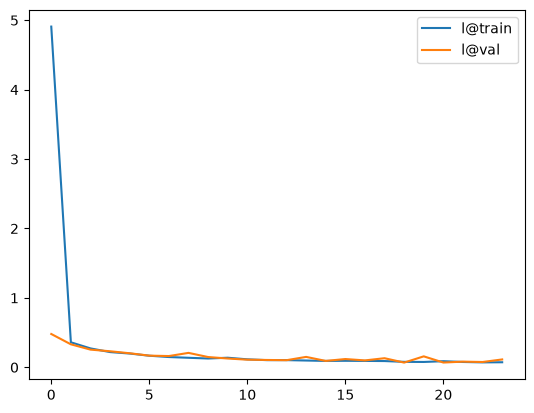

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

d=[]
f=open('files/res_oval.dat')
for s in f:
  d.append([float(x) for x in s.split()])

d=np.array(d)
N=1000
x=np.random.rand(N)
y=5.1*x+3+np.random.rand(N)*0.5

x=d[:,:2]
y=d[:,2]
xtr,xtest,ytr,ytest=train_test_split(x,y) # разделение на обучающую и тестовуб

model=tf.keras.models.Sequential()
model.add(tf.keras.layers.Input(shape=(2,)))
model.add(tf.keras.layers.Dense(1,activation='sigmoid'))
# print(model.summary()) # Кол-во параметров

model=tf.keras.models.Sequential()
model.add(tf.keras.layers.Input(shape=(2,)))
model.add(tf.keras.layers.Dense(4*2,activation='relu')) # *2 из-за relu
model.add(tf.keras.layers.Dense(5*2,activation='relu'))

model.add(tf.keras.layers.Dense(1,activation='sigmoid'))


model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-2),loss='binary_crossentropy',metrics=['accuracy',tf.keras.metrics.AUC(curve='PR',name='aurpc')]) # Инициализаци рандомными числами и Тренировка модели
es=tf.keras.callbacks.EarlyStopping(patience=5,mode='min',monitor='val_loss')
history=model.fit(xtr,ytr,validation_split=0.2,epochs=1000,callbacks=[es])

plt.plot(history.history['loss'],label='l@train')
plt.plot(history.history['val_loss'],label='l@val')
plt.legend()

yp=model.predict(xtest)
tf.keras.utils.plot_model(model,show_layer_activations=True,show_shapes=True,)

## 8. От вероятности к классу: `classification_report`

На выходе стоит `sigmoid`, поэтому `predict` даёт вероятность первого класса. Чтобы получить класс, выбирают порог 0.5: больше — класс 1, меньше или равно — класс 0 (в коде это присваивания по маске прямо в массиве предсказаний).

Качество классификации на несбалансированном датасете смотрят не по `accuracy`, а по **F1** — гармоническому среднему precision и recall:

$$F1 = \frac{2 \cdot P \cdot R}{P + R}$$

`classification_report` печатает precision, recall и F1 по каждому классу, **support** (сколько объектов класса в тестовой выборке) и усреднения. Главное число здесь — **macro avg F1**: среднее F1 по классам, оно не «прячется» за большим классом. По support видно дисбаланс: в нашем прогоне это примерно 1700 объектов одного класса против 721 у другого — отношение больше 1.5, датасет разбалансирован, и высокий `accuracy` в этой ситуации ничего не гарантирует. Macro F1 получился около 0.94, при этом один класс определяется заметно хуже другого.

Precision и recall зависят от порога отсечения: разные пороги дают разные пары (precision, recall), по ним строится кривая, а площадь под ней — это AUC PR.

In [ ]:
from sklearn.metrics import classification_report
ypc=yp
ypc[yp>0.5]=1
ypc[yp<=0.5]=0
print(classification_report(ytest,ypc))

## 9. Матрица ошибок

**Матрица ошибок** (`confusion_matrix`) показывает, куда попал каждый объект: строки — истинные классы, столбцы — предсказанные, на диагонали — правильные ответы. Строится на тестовой выборке одной строкой: `confusion_matrix(ytest, ypc)`.

Из матрицы считаются метрики каждого класса:

- **precision** — какая доля объектов, названных классом, действительно этого класса;
- **recall** — какую долю объектов класса модель нашла.

Матрица сразу показывает, какие классы модель путает: если объекты одного класса «утекают» в другой, это заметно и по расхождению precision и recall в отчёте.

## 10. Полный пайплайн и задание

Порядок работы над задачей такой:

1. получить данные и сразу разделить их на обучающую и тестовую части;
2. обучать модель только на обучающей части (`fit`), валидацию при необходимости выделять из неё же;
3. предсказывать и считать метрики на тестовой части — модель должна работать на данных, которых она не видела;
4. метрики выбирать по задаче: регрессия — лосс (`mse`), классификация — F1 и матрица ошибок, а `accuracy` смотреть только на сбалансированных данных.

**Задание.** Собрать полный пайплайн этого занятия: обучение на обучающей части, предсказание на тестовой, график результата классификации — и построить матрицу ошибок (`confusion_matrix(ytest, ypc)`). Результаты прислать в чат.

---

**Итог занятия 4.** Разобрали, чем TensorFlow отличается от PyTorch и зачем в Keras три уровня API (Sequential, Functional, Subclassing). Собрали первую нейронную сеть: нейрон, полносвязный слой `Dense`, входной слой и функции активации — `linear` для регрессии, `sigmoid` для двух классов. Освоили цикл обучения: `compile` (оптимизатор, лосс, метрики) → `fit` по эпохам → графики `loss`/`val_loss`, отложенную выборку через `validation_split` и раннюю остановку `EarlyStopping`. Решили задачу классификации на `files/res_oval.dat`, добавили скрытые слои с ReLU и разобрали метрики: почему на несбалансированном датасете `accuracy` обманывает, зачем нужны AUC PR и macro F1, как читать `classification_report` и матрицу ошибок.